Population mean = 40.04 min, Population SD = 7.99 min

    n   Mean of sample means    SE = σ/√n   SD of sample means
   10                  40.03         2.53                 2.49
   30                  40.06         1.46                 1.52
  100                  40.01         0.80                 0.81


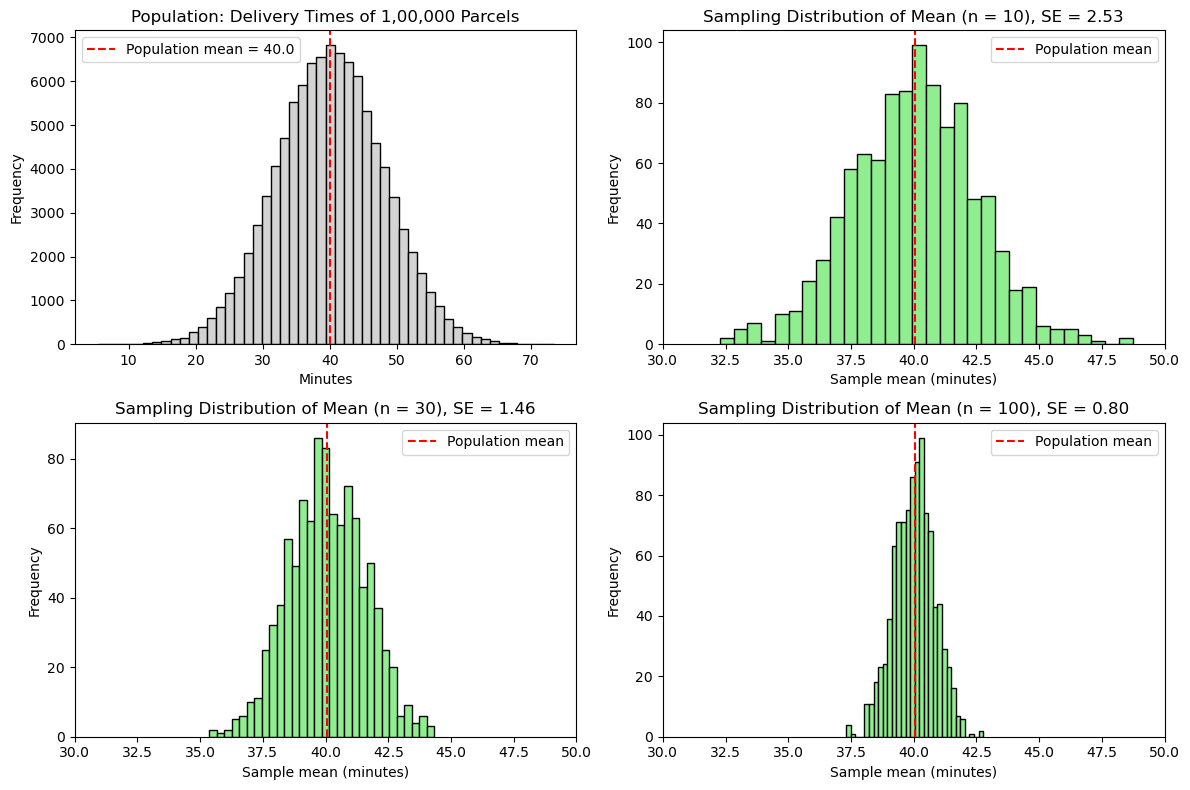


One sample of 30 parcels: mean = 39.50, estimated SE = s/√n = 1.28


In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)


population = np.random.normal(loc=40, scale=8, size=100000)
mu, sigma = population.mean(), population.std()
print(f"Population mean = {mu:.2f} min, Population SD = {sigma:.2f} min\n")


sample_sizes = [10, 30, 100]
num_samples = 1000

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax = ax.ravel()


ax[0].hist(population, bins=50, color='lightgray', edgecolor='black')
ax[0].axvline(mu, color='red', linestyle='--', label=f'Population mean = {mu:.1f}')
ax[0].set_title('Population: Delivery Times of 1,00,000 Parcels')
ax[0].set_xlabel('Minutes')
ax[0].set_ylabel('Frequency')
ax[0].legend()


print(f"{'n':>5} {'Mean of sample means':>22} {'SE = σ/√n':>12} {'SD of sample means':>20}")


for i, n in enumerate(sample_sizes):
    sample_means = [np.random.choice(population, size=n, replace=False).mean() for _ in range(num_samples)]
    se_formula = sigma / np.sqrt(n)
    se_observed = np.std(sample_means)
    
    print(f"{n:>5} {np.mean(sample_means):>22.2f} {se_formula:>12.2f} {se_observed:>20.2f}")
    
    ax[i+1].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
    ax[i+1].axvline(mu, color='red', linestyle='--', label='Population mean')
    ax[i+1].set_xlim(30, 50)  # Same scale so the spread can be compared
    ax[i+1].set_title(f'Sampling Distribution of Mean (n = {n}), SE = {se_formula:.2f}')
    ax[i+1].set_xlabel('Sample mean (minutes)')
    ax[i+1].set_ylabel('Frequency')
    ax[i+1].legend()

plt.tight_layout()
plt.show()


one_sample = np.random.choice(population, size=30, replace=False)
se_est = one_sample.std(ddof=1) / np.sqrt(30)
print(f"\nOne sample of 30 parcels: mean = {one_sample.mean():.2f}, estimated SE = s/√n = {se_est:.2f}")